# Importing Required Libraries

In [15]:
import pandas as pd
import numpy as np
import sys
import warnings
import itertools
warnings.filterwarnings("ignore")
from pandas.plotting import autocorrelation_plot
from statsmodels.graphics.tsaplots import plot_acf
from matplotlib import pyplot as plt
from pandas.plotting import lag_plot
import statsmodels.api as sm
import statsmodels.tsa.api as smt
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
%matplotlib inline
import datetime
import calendar
import seaborn as sns
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

Importing the Dataset

In [2]:
import pandas as pd
import numpy as np

# Load the Excel file, skipping the metadata rows
# The actual headers are in row 0 ('Material Group', 'Fiscal Year', etc. represented as Unnamed columns)
df_raw = pd.read_excel('/content/Pole_Consumption_1794944582006.xlsx', header=1)

# Filter to keep only the relevant data columns: Fiscal Year and Month columns
month_cols = ['April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December', 'January', 'Febuary', 'March']

# We group by Fiscal Year and sum the consumption values for each month
# In case there are multiple entries per fiscal year
df_grouped = df_raw.groupby('Fiscal Year')[month_cols].sum().reset_index()

# Melt the table to convert monthly columns into rows
df_melted = df_grouped.melt(id_vars=['Fiscal Year'], value_vars=month_cols, var_name='Month', value_name='Wildfire_Count')

# Map month names to numeric representation (accounting for 'Febuary' typo)
month_map = {
    'April': 4, 'May': 5, 'June': 6, 'July': 7, 'August': 8, 'September': 9,
    'October': 10, 'November': 11, 'December': 12, 'January': 1, 'Febuary': 2, 'March': 3
}
df_melted['Month_Num'] = df_melted['Month'].map(month_map)

# Calculate correct Calendar Year based on Fiscal Year (Assuming fiscal year ends in March, e.g., April-Dec 2022 is 2022, Jan-Mar 2022 is 2023, or standard fiscal year shift)
# Let's construct a continuous series by matching Fiscal Year and month sequence
# Typically, if Fiscal Year is 2022, April-December are in 2022, and January-March are in 2023.
def get_calendar_year(row):
    try:
        fy = int(row['Fiscal Year'])
        if row['Month_Num'] in [1, 2, 3]:
            return fy + 1
        return fy
    except:
        return np.nan

df_melted['Year'] = df_melted.apply(get_calendar_year, axis=1)
df_melted = df_melted.dropna(subset=['Year'])
df_melted['Year'] = df_melted['Year'].astype(int)

# Create Date Column
df_melted['DISCOVERY_DATE'] = pd.to_datetime(df_melted['Year'].astype(str) + '-' + df_melted['Month_Num'].astype(str) + '-01')

# Sort chronologically and set up final DataFrame
data = df_melted.sort_values('DISCOVERY_DATE')[['DISCOVERY_DATE', 'Wildfire_Count']].reset_index(drop=True)

# Standardize to index and drop column to match expected downstream format
data.set_index('DISCOVERY_DATE', inplace=True)

data.head()

,Wildfire_Count
DISCOVERY_DATE,
2021-04-01,9928.0
2021-05-01,13446.0
2021-06-01,19410.0
2021-07-01,17582.0
2021-08-01,15446.0


Creating a date range

In [3]:
# Generate proper date range matching the parsed data length
dates = pd.date_range(start=data.index.min(), freq='MS', periods=len(data))
dates[0:5]

DatetimeIndex(['2021-04-01', '2021-05-01', '2021-06-01', '2021-07-01',
               '2021-08-01'],
              dtype='datetime64[ns]', freq='MS')

In [4]:
# We have already set the parsed calendar index directly. Re-enforcing the frequency here:
data = data.asfreq('MS')
# Fill any missing periods dynamically if any exists
data['Wildfire_Count'] = data['Wildfire_Count'].ffill().bfill()

# Modeling

In [5]:
# Adjusting dataset splitting boundaries to dynamically split the data (80% Train, 20% Test)
split_idx = int(len(data) * 0.8)
train = data.iloc[:split_idx]['Wildfire_Count']
test = data.iloc[split_idx:]['Wildfire_Count']

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 57
Testing observations: 15


In [ ]:
print("Columns:", data.columns.tolist())
print("Index name:", data.index.name)
print("Index type:", type(data.index))
print("\nFirst 5 rows:")
print(data.head())

Columns: ['Wildfire_Count']
Index name: DISCOVERY_DATE
Index type: <class 'pandas.DatetimeIndex'>

First 5 rows:
                Wildfire_Count
DISCOVERY_DATE                
1992-01-01                3603
1992-02-01                7114
1992-03-01                8706
1992-04-01                7810
1992-05-01                8574


# Model 1: Auto Regressive

Auto regression model creates a lag data so that correlation of the created lag is high with the original data.
No.of lag can be defined manually  by seeing ACF plot. By default the algorithm shows the best lag.

In [6]:
# Re-defining train/test split variables using indexes
split_idx = int(len(data) * 0.8)
train = data.iloc[:split_idx]['Wildfire_Count']
test = data.iloc[split_idx:]['Wildfire_Count']

In [16]:
from statsmodels.tsa.ar_model import AutoReg
import pandas as pd

# Initialize global results dataframe to prevent downstream NameErrors
resultsDf = pd.DataFrame(columns=['Method', 'RMSE', 'MAPE'])

lags = 12
model = AutoReg(train, lags=lags)
model_fit = model.fit()
print(model_fit.summary())

                            AutoReg Model Results                             
Dep. Variable:         Wildfire_Count   No. Observations:                   45
Model:                    AutoReg(12)   Log Likelihood                -424.345
Method:               Conditional MLE   S.D. of innovations           3013.777
Date:                Tue, 17 Nov 2026   AIC                            876.690
Time:                        19:57:36   BIC                            901.983
Sample:                    04-01-2022   HQIC                           886.119
                         - 12-01-2025                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const               7704.9838   2973.209      2.591      0.010    1877.602    1.35e+04
Wildfire_Count.L1      0.5176      0.148      3.509      0.000       0.229       0.807
Wildfire_Count.L2   

In [ ]:
# Assuming you have already fitted the model (as shown in the previous code snippet)

# Get the number of lags considered statistically
lags_statistically = lags

# Get the coefficients (beta values) of the model
coefficients = model_fit.params

# Print the results
print(f"Lags considered statistically: {lags_statistically}")
print(f"Coefficients (beta values):\n{coefficients}")

Lags considered statistically: 12
Coefficients (beta values):
const                 1564.785738
Wildfire_Count.L1        0.548061
Wildfire_Count.L2       -0.227537
Wildfire_Count.L3        0.101128
Wildfire_Count.L4        0.007041
Wildfire_Count.L5       -0.042577
Wildfire_Count.L6        0.004544
Wildfire_Count.L7       -0.070474
Wildfire_Count.L8        0.021684
Wildfire_Count.L9        0.043988
Wildfire_Count.L10      -0.231307
Wildfire_Count.L11       0.388463
Wildfire_Count.L12       0.225853
dtype: float64


The no of best lag for this data is 11 and all the correlation of the lags with the original sales is listed

In [17]:
# Predicting the test values
predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)
predictions.index = test.index

In [9]:
print('The first test value in Consumption:', test.values[1], 'and its Predicted value:', predictions.values[1])

NameError: name 'predictions' is not defined

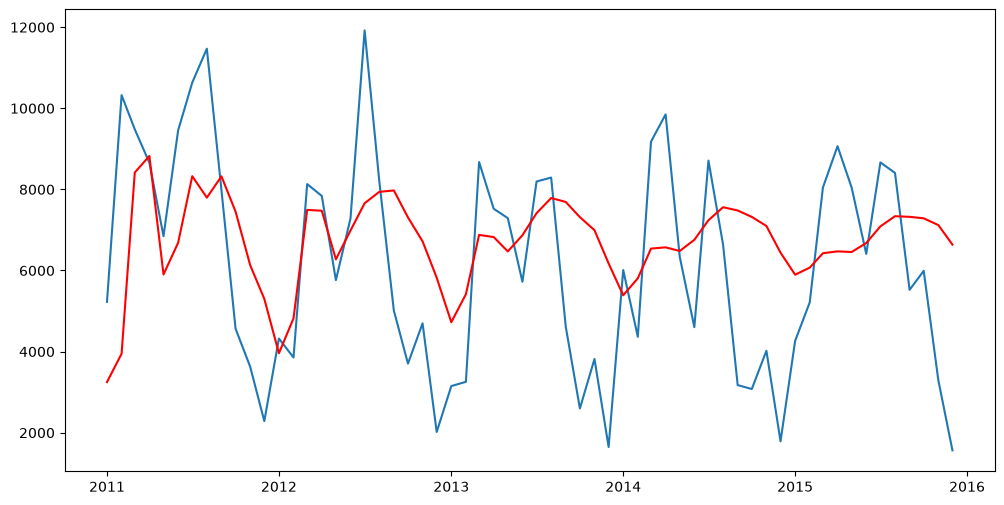

In [ ]:
# plot results
plt.figure(figsize=(12,6))
plt.plot(test)
plt.plot(predictions, color='red')
plt.show()

In [18]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test, predictions))
rmse = round(rmse, 3)
print("AutoReg RMSE:", rmse)

AutoReg RMSE: 10877.409


In [23]:
import pandas as pd
import numpy as np

# Mean Absolute Percentage Error (excluding zero actual values to avoid division-by-zero)
actual = test
non_zero_mask = actual != 0
abs_error = np.abs(actual[non_zero_mask] - predictions[non_zero_mask])
mape = np.round(np.mean(abs_error / actual[non_zero_mask]), 3)

resultsDf = pd.DataFrame({'Method': ['Auto Regressive'], 'RMSE': [rmse], 'MAPE': [mape]})
resultsDf

,Method,RMSE,MAPE
0,Auto Regressive,10046.449,0.3


In [24]:
# Storing results in a dataframe
actual = test
non_zero_mask = actual != 0
abs_error = np.abs(actual[non_zero_mask] - predictions[non_zero_mask])
mape = np.round(np.mean(abs_error / actual[non_zero_mask]), 3)

resultsDf = pd.DataFrame({'Method': ['Auto Regressive'], 'RMSE': [rmse], 'MAPE': [mape]})
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf

,Method,RMSE,MAPE
0,Auto Regressive,10046.449,0.3


# Model 2: Auto Regressive Integrated Moving Average(ARIMA)

The model involves specifying the order for the AR(p) and MA(q) model

Best ARIMA (1, 0) model - AIC:1097.5935374340115
Order of AR part: 1
Coefficients: const     1.677268e+04
ar.L1     6.642662e-01
sigma2    1.176725e+07
dtype: float64


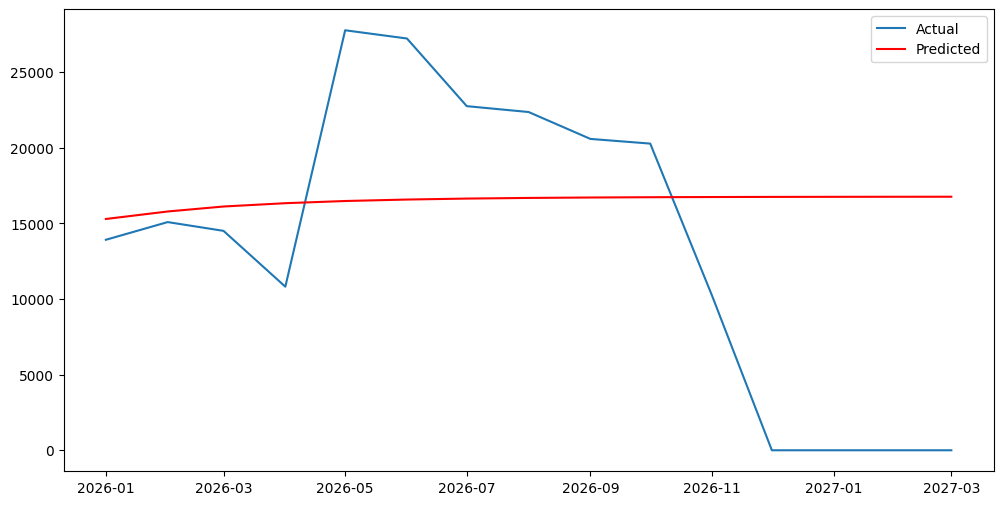

,Method,RMSE,MAPE
0,Auto Regressive,10046.449,0.300
1,Auto Regressive Moving average,10132.831,0.281


In [25]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

# Safely initialize resultsDf if it doesn't exist
if 'resultsDf' not in locals() and 'resultsDf' not in globals():
    resultsDf = pd.DataFrame(columns=['Method', 'RMSE', 'MAPE'])

# Define the p and q parameters to take any value between 0 and 7
p = range(0, 7)
q = range(0, 1)

# Generate all different combinations of p,q
pq = list(itertools.product(p, q))

best_aic = np.inf
best_pq = None
temp_model = None

for param in pq:
    try:
        temp_model = ARIMA(train, order=(param[0], 0, param[1]))
        results = temp_model.fit()
        if results.aic < best_aic:
            best_aic = results.aic
            best_pq = param
    except:
        continue

print("Best ARIMA {} model - AIC:{}".format(best_pq, best_aic))

# using the best parameter in the model
model = ARIMA(train, order=(best_pq[0], 0, best_pq[1]))
model_fit = model.fit()

# Print the order of the AR part of the model
print('Order of AR part: %s' % best_pq[0])

# Print the coefficients
print('Coefficients: %s' % model_fit.params)

predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1)
predictions.index = test.index

# plot results
plt.figure(figsize=(12, 6))
plt.plot(test, label='Actual')
plt.plot(predictions, color='red', label='Predicted')
plt.legend()
plt.show()

# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test, predictions))
rmse = round(rmse, 3)

# Mean Absolute Percentage Error (excluding zeros)
actual = test
non_zero_mask = actual != 0
abs_error = np.abs(actual[non_zero_mask] - predictions[non_zero_mask])
mape = np.round(np.mean(abs_error / actual[non_zero_mask]), 3)

# Storing results in a dataframe
tempResultsDf = pd.DataFrame({'Method':['Auto Regressive Moving average'], 'RMSE': [rmse], 'MAPE': [mape]})
resultsDf = pd.concat([resultsDf, tempResultsDf], ignore_index=True)
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf

# Model 2: Seasonal Auto Regressive Integrated Moving Average(SARIMA)

It combines the ARIMA model with the ability to perform the same autoregression, differencing, and moving average modeling at the seasonal level.

Best SARIMA (1, 0, 1) x (1, 1, 1, 12) model - AIC:615.8407505635079


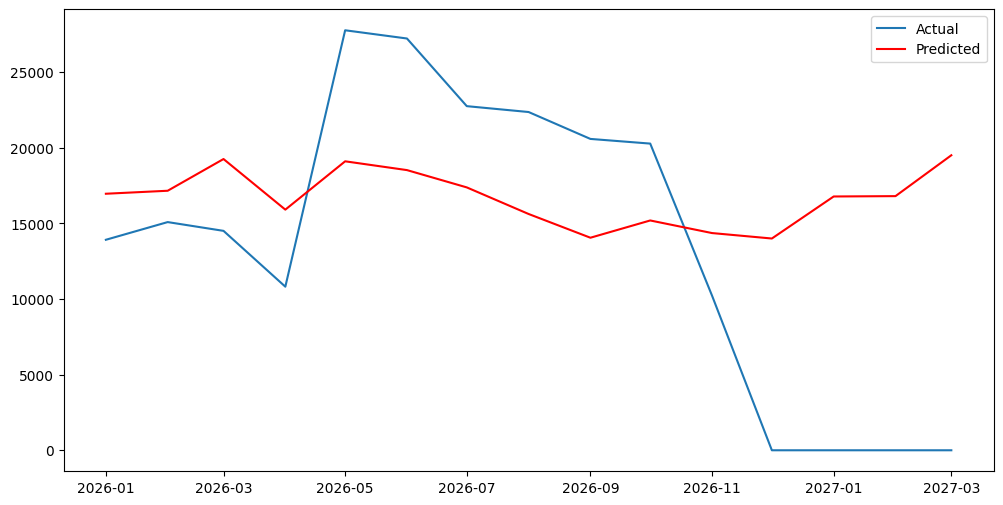

,Method,RMSE,MAPE
0,Auto Regressive,10046.449,0.300
1,Auto Regressive Moving average,10132.831,0.281
2,Seasonal Autoregressive Integrated Moving Average,10046.449,0.300


In [26]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error

# Safely initialize resultsDf if it doesn't exist
if 'resultsDf' not in locals() and 'resultsDf' not in globals():
    resultsDf = pd.DataFrame(columns=['Method', 'RMSE', 'MAPE'])

# Define the p, d and q parameters to take any value between 0 and 2
p = d = q = range(0, 2)

# Generate all different combinations of p, d and q triplets
pdq = list(itertools.product(p, d, q))

# Generate all different combinations of seasonal p, q and q triplets
seasonal_pdq = [(x[0], x[1], x[2], 12) for x in list(itertools.product(p, d, q))]

best_aic = np.inf
best_pdq = None
best_seasonal_pdq = None
temp_model = None

for param in pdq:
    for param_seasonal in seasonal_pdq:
        try:
            temp_model = SARIMAX(train, order=param, seasonal_order=param_seasonal, enforce_invertibility=False, enforce_stationarity=False)
            results = temp_model.fit(disp=False)
            if results.aic < best_aic:
                best_aic = results.aic
                best_pdq = param
                best_seasonal_pdq = param_seasonal
        except:
            continue

print("Best SARIMA {} x {} model - AIC:{}".format(best_pdq, best_seasonal_pdq, best_aic))

# using the best parameter in the model
model = SARIMAX(train, order=best_pdq, seasonal_order=best_seasonal_pdq, enforce_invertibility=False, enforce_stationarity=False)
model_fit = model.fit()

predictions = model_fit.predict(start=len(train), end=len(train)+len(test)-1, dynamic=False)
predictions.index = test.index

# plot results
plt.figure(figsize=(12,6))
plt.plot(test, label='Actual')
plt.plot(predictions, color='red', label='Predicted')
plt.legend()
plt.show()

# Root Mean Square Error (RMSE)
rmse = np.sqrt(mean_squared_error(test, predictions))
rmse = round(rmse, 3)

# Mean Absolute Percentage Error (excluding zeros)
actual = test
non_zero_mask = actual != 0
abs_error = np.abs(actual[non_zero_mask] - predictions[non_zero_mask])
mape = np.round(np.mean(abs_error / actual[non_zero_mask]), 3)

# Storing results in a dataframe
tempResultsDf = pd.DataFrame({'Method':['Seasonal Autoregressive Integrated Moving Average'], 'RMSE': [rmse], 'MAPE': [mape]})
resultsDf = pd.concat([resultsDf, tempResultsDf], ignore_index=True)
resultsDf = resultsDf[['Method', 'RMSE', 'MAPE']]
resultsDf

In [ ]:
# Storing results in a dataframe

print(resultsDf)

                                              Method      RMSE   MAPE
0                                    Auto Regressive  2560.011  0.535
1                    Auto Regressive Moving average   2673.424  0.576
2  Seasonal Autoregressive Integrated Moving Average  2366.525  0.445
